# TIRT with person and statement covariates

Compare two models of the **same 80 respondents and nine dyads**. The baseline
uses the default population and measurement priors. The explanatory model adds
person predictors of ability and a statement predictor of FC loading magnitude.
These are synthetic teaching data; the analysis is about associations.

## Model

For a dyad containing statements $i$ and $j$, response 1 prefers $i$:

$$
m_{ps}=\lambda_s\theta_{p,d(s)}+\delta_s,
\qquad \lambda_s=\operatorname{key}_s a_s,\quad a_s>0.
$$

$$
P(Y_{pb}=1\mid\theta_p)=\Phi\!\left(
\frac{m_{pi}-m_{pj}-c_b}{\sqrt{\psi_i+\psi_j}}\right).
$$

Here $a_s$ is loading magnitude, $\delta_s$ a statement effect, $c_b$ a pair
cutpoint and $\psi_s$ a residual variance. The trait correlation matrix has the default LKJ(1) prior.

The baseline has $\theta_p\sim\mathcal N(0,R)$ and the default independent
$\log a_s\sim\mathcal N(0,0.5^2)$. The explanatory model instead uses

$$
\begin{aligned}
\theta_{pk}&=b_{hk}(h_p-\bar h)
+b_{ck}\,1(\mathrm{course\_format}_p=\mathrm{online})+\epsilon_{pk},
&\epsilon_p&\sim\mathcal N(0,R),\\
\log a_s&=\gamma_0+\gamma_1(\log\ell_s-\overline{\log\ell})+u_s,
&u_s&\sim\mathcal N(0,\tau_a^2).
\end{aligned}
$$

Practice $h_p$ is measured in hours; `in_person` is the explicit reference course
format. Numeric predictors are centered on the calibration cohort and retain
their units. There is no separate ability regression intercept: the population
reference mean supplies zero. The loading regression includes its default
intercept and remaining SD. All priors come from the current model defaults;
adding a loading regression replaces its independent loading prior with this
conditional lognormal law.

## Identification

The stored keying fixes loading orientation. This dyad design fixes statement
residual variances to 0.5 and population residual SDs to one. At centered practice
hours and the reference course format, the population mean is zero. Both models
use noncentered ability coordinates. The complete summaries below show the fixed
references and remaining priors.


In [2]:
import logging
import warnings

import arviz as az
import arviz_plots as azp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import pyfcirt as fc

sns.set_theme(style="ticks")
logging.getLogger("pymc").setLevel(logging.WARNING)

## Load one matched cohort

One installed bundle supplies answers, design, person covariates and statement
features. `n_persons=80` selects the same first source people in all person tables;
rows align by IDs, independently of file order. No data are fetched separately.

`practice_hours` retains the original synthetic values. `course_format` was
randomized independently after the responses were generated (seed 2026111701);
it is a hypothetical teaching label, not an observed demographic or a causal
assignment used by the response generator. Its generator and the original
response-generation note are saved in the resource named by
`example.metadata["generation_resource"]`.

The original positive `likert_loading` feature represents a **known Likert
discrimination predictor** in this simulated setup. No empirical Likert
calibration or rating responses are supplied. Its log is a statement-level
predictor; `fc.loading_magnitude` is the FC response parameter being predicted.
Neither variable is a person trait. We reuse the original feature values rather
than generating new discrimination estimates from these FC answers.

In [3]:
example = fc.load_example("custom_tirt", model=fc.TIRT(), n_persons=80)
people = example.person_data.assign(
    course_format=lambda frame: pd.Categorical(
        frame.course_format, categories=["in_person", "online"]
    )
)
statements = example.data.statement_features.assign(
    log_likert_loading=lambda frame: np.log(frame.likert_loading)
)

display(example.data.responses.frame.head(5))
display(example.data.design.head(5))
display(people.head(5))
display(statements.head(5))
print(example.metadata["companion_tables"])

,person_id,block_id,statement_1,statement_2,response
0,P001,B1,S1,S2,0
1,P001,B2,S3,S4,0
2,P001,B3,S5,S6,1
3,P001,B4,S7,S8,0
4,P001,B5,S9,S10,0


,block_id,position,statement_id,trait,keying
0,B1,1,S1,theta1,1
1,B1,2,S2,theta2,1
2,B2,1,S3,theta2,1
3,B2,2,S4,theta3,-1
4,B3,1,S5,theta3,1


,person_id,practice_hours,course_format
0,P069,6.982071,online
1,P044,19.256301,online
2,P051,13.478059,in_person
3,P041,10.258190,in_person
4,P028,1.543173,in_person


,statement_id,likert_loading,log_likert_loading
0,S11,1.009208,0.009166
1,S7,0.879866,-0.127985
2,S8,0.649168,-0.432064
3,S6,1.261469,0.232277
4,S12,1.260171,0.231247


{'person_data': 'custom_tirt/people.csv'}


## Define and inspect both models

Prepare the responses once and reuse them for independent model objects. Adding
regressions changes the explanatory model's prepared configuration, leaving the
baseline intact. Missing features must be resolved before declaring formulas.
The native summaries report the resolved priors, including the automatic
predictor-scale adjustments to default coefficient priors.

In [4]:
prepared = fc.PreparedInputs.from_inputs(example.data, theta_parameterization="noncentered")
baseline = fc.Model(prepared)
model = fc.Model(prepared)
model.add_regressions(
    """
    theta ~ practice_hours + course_format
    fc.loading_magnitude ~ log_likert_loading
    """,
    person_data=people,
    statement_data=statements,
)
for name, fitted in [("Without covariates", baseline), ("With covariates", model)]:
    print(name)
    print(fitted.summary())

Without covariates
Model: TIRT
80 people, 3 traits, 9 blocks, 18 statements
Observations: 720 pair comparisons
Measurements:
  9 blocks, size=2, link=probit
Population:
  theta ~ MvNormal(mu=0, cov=R)
  R [3 x 3] ~ LKJCorr(n=3, eta=1)
Priors:
    loading [18] ~ LogNormal(mu=0, sigma=0.5)
    statement_effect [18] ~ Normal(mu=0, sigma=sqrt(residual_variance))
    cutpoint [9] ~ Normal(mu=0, sigma=1)
Constraints:
    residual_variance: fixed=0.5 [18 fixed]
With covariates
Model: TIRT
80 people, 3 traits, 9 blocks, 18 statements
Observations: 720 pair comparisons
Measurements:
  9 blocks, size=2, link=probit
Population:
  theta ~ MvNormal(mu=X @ regression_coefficient, cov=R)
  theta ~ practice_hours + course_format
  R [3 x 3] ~ LKJCorr(n=3, eta=1)
  regression_coefficient [3] ~ Normal(mu=0, sigma=0.1645699306461495)
  regression_coefficient [3] ~ Normal(mu=0, sigma=1)
Regression: loading ~ log_likert_loading
  log-loading; 1 independent parameter pool(s)
Priors:
    loading [18] ~ condi

## Fit and diagnose before interpretation

The two calls use the same frozen observations, current default priors and
noncentered ability coordinates. Each retains 3,000 draws per chain after 1,500
warmup iterations, using four chains and target acceptance 0.8. This is a starting
configuration, not evidence of convergence. Inspect all parameter families:
R-hat near one, adequate bulk/tail ESS and small MCSE are needed alongside
no divergences. Investigate poor geometry before merely increasing draws.

As working checks, seek R-hat below 1.01, bulk/tail ESS above 400 and MCSE of the mean below 5% of posterior SD. Fixed references have undefined sampling diagnostics; the overview omits those rows. The distribution and rank plots illustrate two loading entries from each model; the numerical overview covers every saved family.

In [ ]:
baseline.fit(draws=3000, tune=1500, chains=4, target_accept=0.8, random_seed=2026111702)
model.fit(draws=3000, tune=1500, chains=4, target_accept=0.8, random_seed=2026111703)

In [4]:
for name, fitted in [("Baseline", baseline), ("Explanatory", model)]:
    posterior = fitted.idata["posterior"].to_dataset().reset_coords(drop=True)
    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore", "invalid value encountered in scalar divide", RuntimeWarning
        )
        diagnostics = az.summary(posterior, fmt="xarray", round_to="none")
    # Each row summarizes one parameter family over its own labelled axes.
    extrema = pd.DataFrame(
        {
            "Maximum R-hat": diagnostics.sel(summary="r_hat").max().to_array().to_series(),
            "Minimum bulk ESS": diagnostics.sel(summary="ess_bulk").min().to_array().to_series(),
            "Minimum tail ESS": diagnostics.sel(summary="ess_tail").min().to_array().to_series(),
        }
    ).rename_axis("Parameter")
    sd = diagnostics.sel(summary="sd", drop=True)
    relative_mcse = diagnostics.sel(summary="mcse_mean", drop=True) / sd.where(sd > 0)
    print(name)
    display(extrema.round(3))
    display(
        pd.Series(
            {
                "Maximum R-hat": f"{extrema['Maximum R-hat'].max():.3f}",
                "Minimum bulk ESS": f"{extrema['Minimum bulk ESS'].min():,.0f}",
                "Minimum tail ESS": f"{extrema['Minimum tail ESS'].min():,.0f}",
                "Maximum MCSE(mean) / SD": f"{relative_mcse.max().to_array().max().item():.1%}",
                "Divergences": str(int(fitted.idata["sample_stats"]["diverging"].sum().item())),
            }
        ).to_frame("Value")
    )

Baseline
Explanatory


,Maximum R-hat,Minimum bulk ESS,Minimum tail ESS
Parameter,,,
loading,1.001,3466.619,5626.521
statement_effect,1.001,12742.219,8994.863
cutpoint,1.001,11041.278,8620.940
trait_correlation,1.003,1373.227,2593.463
covariance,1.003,1373.227,2593.463
theta,1.002,5304.241,5895.363


,Value
Maximum R-hat,1.003
Minimum bulk ESS,"1,373"
Minimum tail ESS,"2,593"
Maximum MCSE(mean) / SD,2.7%
Divergences,0


,Maximum R-hat,Minimum bulk ESS,Minimum tail ESS
Parameter,,,
regression_coefficient,1.003,2876.373,5004.184
regression_sd,1.001,1934.983,2597.799
loading,1.002,2888.403,4086.643
statement_effect,1.001,9300.174,8223.940
cutpoint,1.001,8092.534,7538.232
trait_correlation,1.006,1494.123,2699.523
covariance,1.006,1494.123,2699.523
theta,1.001,5664.054,6326.026


,Value
Maximum R-hat,1.006
Minimum bulk ESS,"1,494"
Minimum tail ESS,"2,598"
Maximum MCSE(mean) / SD,2.6%
Divergences,0


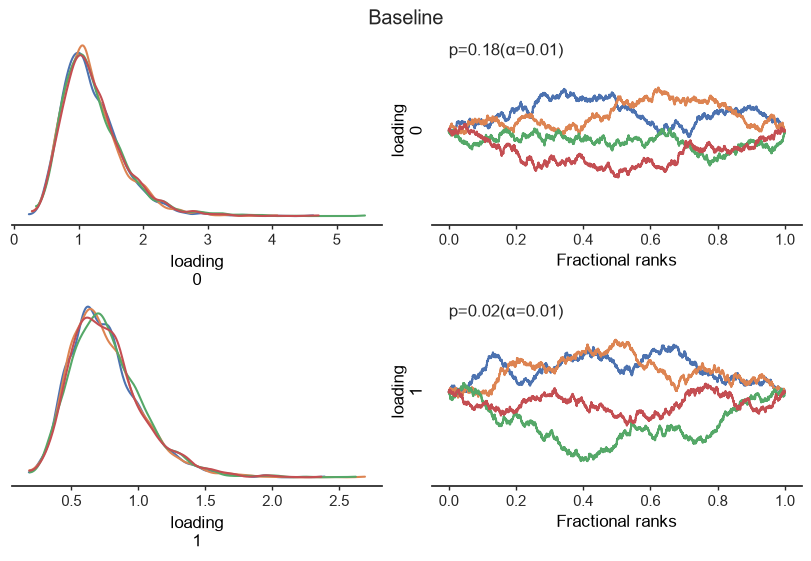

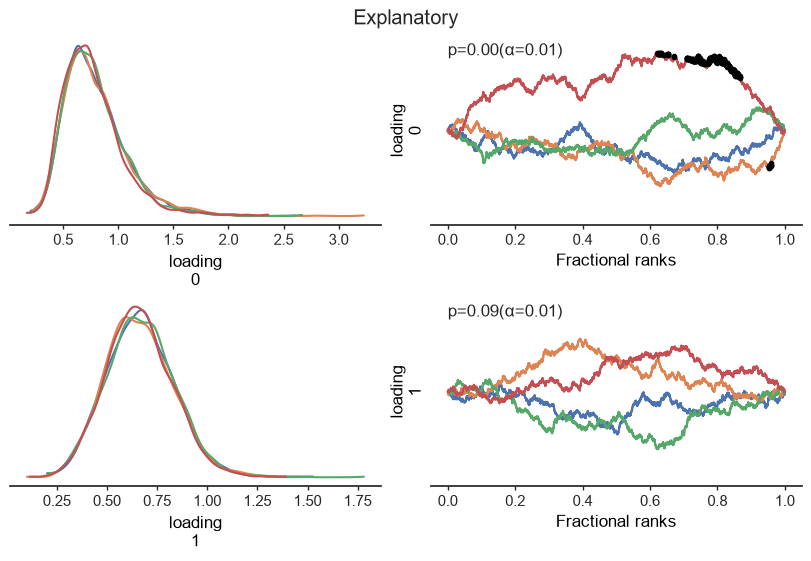

In [5]:
for name, fitted in [("Baseline", baseline), ("Explanatory", model)]:
    loading_ids = fitted.idata["posterior"].loading_id.values[:2]
    azp.plot_rank_dist(
        fitted.idata,
        var_names=["loading"],
        coords={"loading_id": loading_ids},
        compact=False,
        backend="matplotlib",
        figure_kwargs={"figsize": (8, 5.5), "layout": "constrained"},
    )
    plt.gcf().suptitle(name)
    plt.show()

Both runs meet the working precision checks. Maximum R-hat is 1.003 for the baseline and 1.006 for the explanatory model; minimum bulk/tail ESS is 1,373/2,593 and 1,494/2,598, respectively. Neither run has divergences. The largest MCSE of a posterior mean is 2.7% and 2.6% of its posterior SD. Inspect the selected loading distributions and rank plots alongside this overview before reading the regression results.

## Interpret person and statement associations

Only interpret coefficients after examining diagnostics. The person slopes give
trait differences per additional hour and for `online` relative to `in_person`,
conditional on the other predictor. The course label has no generating effect;
finite-sample associations can still occur. The statement slope describes how
log FC loading magnitude varies with log known Likert discrimination. It is not
a test of equivalence between the two measurement formats.

The full regression table includes loading intercept, slope and remaining SD
as well as all ability slopes. Compare intervals with zero and their widths;
do not infer absence of an association solely from an interval crossing zero.

The tables retain fixed references as well as estimated values. Hours and log-loading predictors use different units, so interpret slopes on their own target scales. The forest plot shows posterior means with 50% and 95% HDIs.

Baseline — full measurement coefficients


mean 
 sd 
 hdi95_lb 
 hdi95_ub 
 ess_bulk 
 ess_tail 
 r_hat 
 mcse_mean 
 mcse_sd 
 
 
 unit 
 statement 
 trait 
 pair 
 position 
 parameter 
 
 
 
 
 
 
 
 
 
 
 
 
 
 B1 
 S1 
 theta1 
 NaN 
 NaN 
 loading 
 1.225 
 0.482 
 0.454 
 2.170 
 3466.619 
 5626.521 
 1.000 
 0.008 
 0.007 
 
 
 S2 
 theta2 
 NaN 
 NaN 
 loading 
 0.763 
 0.274 
 0.308 
 1.327 
 5583.758 
 6937.551 
 1.000 
 0.004 
 0.003 
 
 
 S1 
 theta1 
 NaN 
 NaN 
 residual_variance 
 0.5 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 
 
 S2 
 theta2 
 NaN 
 NaN 
 residual_variance 
 0.5 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 
 
 nan 
 nan 
 S1 > S2 
 1 
 cutpoint 
 -0.148 
 0.713 
 -1.562 
 1.215 
 11376.995 
 9269.707 
 1.000 
 0.007 
 0.006 
 
 
 B2 
 S3 
 theta2 
 NaN 
 NaN 
 loading 
 1.443 
 0.487 
 0.599 
 2.394 
 8535.364 
 8676.655 
 1.000 
 0.005 
 0.005 
 
 
 S4 
 theta3 
 NaN 
 NaN 
 loading 
 1.608 
 0.522 
 0.722 
 2.673 
 6496.454 
 8291.519 
 1.001 
 0.006 
 0.005 
 
 
 S3 
 theta2 
 NaN 
 NaN 
 residual_variance 
 0.5 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 
 
 S4 
 theta3 
 NaN 
 NaN 
 residual_variance 
 0.5 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 
 
 nan 
 nan 
 S3 > S4 
 1 
 cutpoint 
 0.255 
 0.726 
 -1.124 
 1.718 
 11568.524 
 9031.599 
 1.000 
 0.007 
 0.007 
 
 
 B3 
 S5 
 theta3 
 NaN 
 NaN 
 loading 
 1.009 
 0.340 
 0.431 
 1.677 
 5076.911 
 6187.347 
 1.000 
 0.005 
 0.004 
 
 
 S6 
 theta1 
 NaN 
 NaN 
 loading 
 1.148 
 0.422 
 0.426 
 1.962 
 5597.335 
 6727.385 
 1.001 
 0.006 
 0.005 
 
 
 S5 
 theta3 
 NaN 
 NaN 
 residual_variance 
 0.5 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 
 
 S6 
 theta1 
 NaN 
 NaN 
 residual_variance 
 0.5 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 
 
 nan 
 nan 
 S5 > S6 
 1 
 cutpoint 
 0.308 
 0.727 
 -1.122 
 1.720 
 12002.969 
 8620.940 
 1.000 
 0.007 
 0.007 
 
 
 B4 
 S7 
 theta1 
 NaN 
 NaN 
 loading 
 0.634 
 0.237 
 0.237 
 1.101 
 8792.281 
 8166.364 
 1.000 
 0.003 
 0.003 
 
 
 S8 
 theta2 
 NaN 
 NaN 
 loading 
 1.140 
 0.406 
 0.477 
 1.975 
 6537.032 
 7764.583 
 1.001 
 0.005 
 0.005 
 
 
 S7 
 theta1 
 NaN 
 NaN 
 residual_variance 
 0.5 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 
 
 S8 
 theta2 
 NaN 
 NaN 
 residual_variance 
 0.5 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 
 
 nan 
 nan 
 S7 > S8 
 1 
 cutpoint 
 -0.644 
 0.721 
 -2.094 
 0.717 
 11041.278 
 9294.296 
 1.000 
 0.007 
 0.006 
 
 
 B5 
 S9 
 theta2 
 NaN 
 NaN 
 loading 
 1.688 
 0.595 
 0.681 
 2.872 
 4981.599 
 6978.621 
 1.000 
 0.008 
 0.007 
 
 
 S10 
 theta3 
 NaN 
 NaN 
 loading 
 0.947 
 0.352 
 0.385 
 1.692 
 5404.079 
 7599.484 
 1.001 
 0.005 
 0.004 
 
 
 S9 
 theta2 
 NaN 
 NaN 
 residual_variance 
 0.5 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 
 
 S10 
 theta3 
 NaN 
 NaN 
 residual_variance 
 0.5 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 
 
 nan 
 nan 
 S9 > S10 
 1 
 cutpoint 
 -0.305 
 0.727 
 -1.757 
 1.101 
 12037.000 
 9443.874 
 1.000 
 0.007 
 0.006 
 
 
 B6 
 S11 
 theta3 
 NaN 
 NaN 
 loading 
 1.515 
 0.540 
 0.610 
 2.601 
 5578.203 
 7350.556 
 1.000 
 0.007 
 0.006 
 
 
 S12 
 theta1 
 NaN 
 NaN 
 loading 
 1.339 
 0.537 
 0.443 
 2.405 
 5409.665 
 6946.150 
 1.000 
 0.007 
 0.007 
 
 
 S11 
 theta3 
 NaN 
 NaN 
 residual_variance 
 0.5 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 
 
 S12 
 theta1 
 NaN 
 NaN 
 residual_variance 
 0.5 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 
 
 nan 
 nan 
 S11 > S12 
 1 
 cutpoint 
 -0.101 
 0.723 
 -1.468 
 1.360 
 11300.487 
 8787.019 
 1.001 
 0.007 
 0.006 
 
 
 B7 
 S13 
 theta1 
 NaN 
 NaN 
 loading 
 0.478 
 0.174 
 0.185 
 0.816 
 8365.709 
 8598.504 
 1.000 
 0.002 
 0.002 
 
 
 S14 
 theta2 
 NaN 
 NaN 
 loading 
 1.005 
 0.360 
 0.408 
 1.727 
 4836.156 
 6416.998 
 1.000 
 0.005 
 0.005 
 
 
 S13 
 theta1 
 NaN 
 NaN 
 residual_variance 
 0.5 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 
 
 S14 
 theta2 
 NaN 
 NaN 
 residual_variance 


Baseline — full regression coefficients


,,mean,sd,hdi95_lb,hdi95_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
trait,parameter,,,,,,,,,
theta1,Intercept,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
theta2,Intercept,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
theta3,Intercept,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Explanatory — full measurement coefficients


mean 
 sd 
 hdi95_lb 
 hdi95_ub 
 ess_bulk 
 ess_tail 
 r_hat 
 mcse_mean 
 mcse_sd 
 
 
 unit 
 statement 
 trait 
 pair 
 position 
 parameter 
 
 
 
 
 
 
 
 
 
 
 
 
 
 B1 
 S1 
 theta1 
 NaN 
 NaN 
 loading 
 0.785 
 0.282 
 0.327 
 1.349 
 2919.763 
 4086.643 
 1.001 
 0.005 
 0.005 
 
 
 S2 
 theta2 
 NaN 
 NaN 
 loading 
 0.665 
 0.169 
 0.333 
 0.982 
 5429.131 
 7546.524 
 1.002 
 0.002 
 0.001 
 
 
 S1 
 theta1 
 NaN 
 NaN 
 residual_variance 
 0.5 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 
 
 S2 
 theta2 
 NaN 
 NaN 
 residual_variance 
 0.5 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 
 
 nan 
 nan 
 S1 > S2 
 1 
 cutpoint 
 -0.085 
 0.723 
 -1.527 
 1.292 
 8547.983 
 7796.996 
 1.001 
 0.008 
 0.007 
 
 
 B2 
 S3 
 theta2 
 NaN 
 NaN 
 loading 
 1.453 
 0.423 
 0.738 
 2.281 
 5244.365 
 6496.327 
 1.001 
 0.006 
 0.006 
 
 
 S4 
 theta3 
 NaN 
 NaN 
 loading 
 1.436 
 0.448 
 0.730 
 2.327 
 3308.596 
 5815.993 
 1.001 
 0.008 
 0.007 
 
 
 S3 
 theta2 
 NaN 
 NaN 
 residual_variance 
 0.5 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 
 
 S4 
 theta3 
 NaN 
 NaN 
 residual_variance 
 0.5 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 
 
 nan 
 nan 
 S3 > S4 
 1 
 cutpoint 
 0.238 
 0.738 
 -1.170 
 1.712 
 8134.366 
 7710.547 
 1.001 
 0.008 
 0.007 
 
 
 B3 
 S5 
 theta3 
 NaN 
 NaN 
 loading 
 0.929 
 0.237 
 0.502 
 1.424 
 4490.915 
 6107.392 
 1.002 
 0.004 
 0.003 
 
 
 S6 
 theta1 
 NaN 
 NaN 
 loading 
 1.088 
 0.290 
 0.562 
 1.673 
 5226.589 
 6563.022 
 1.001 
 0.004 
 0.004 
 
 
 S5 
 theta3 
 NaN 
 NaN 
 residual_variance 
 0.5 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 
 
 S6 
 theta1 
 NaN 
 NaN 
 residual_variance 
 0.5 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 
 
 nan 
 nan 
 S5 > S6 
 1 
 cutpoint 
 0.312 
 0.722 
 -1.101 
 1.742 
 8962.477 
 8364.849 
 1.000 
 0.008 
 0.007 
 
 
 B4 
 S7 
 theta1 
 NaN 
 NaN 
 loading 
 0.683 
 0.191 
 0.310 
 1.052 
 6452.520 
 7881.564 
 1.000 
 0.002 
 0.002 
 
 
 S8 
 theta2 
 NaN 
 NaN 
 loading 
 0.752 
 0.238 
 0.353 
 1.240 
 5394.946 
 8029.053 
 1.000 
 0.003 
 0.003 
 
 
 S7 
 theta1 
 NaN 
 NaN 
 residual_variance 
 0.5 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 
 
 S8 
 theta2 
 NaN 
 NaN 
 residual_variance 
 0.5 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 
 
 nan 
 nan 
 S7 > S8 
 1 
 cutpoint 
 -0.636 
 0.724 
 -2.099 
 0.709 
 8831.484 
 8422.027 
 1.001 
 0.008 
 0.007 
 
 
 B5 
 S9 
 theta2 
 NaN 
 NaN 
 loading 
 2.008 
 0.697 
 0.908 
 3.399 
 2888.403 
 5089.303 
 1.000 
 0.013 
 0.011 
 
 
 S10 
 theta3 
 NaN 
 NaN 
 loading 
 1.248 
 0.378 
 0.566 
 1.985 
 4265.776 
 6148.514 
 1.001 
 0.006 
 0.005 
 
 
 S9 
 theta2 
 NaN 
 NaN 
 residual_variance 
 0.5 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 
 
 S10 
 theta3 
 NaN 
 NaN 
 residual_variance 
 0.5 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 
 
 nan 
 nan 
 S9 > S10 
 1 
 cutpoint 
 -0.483 
 0.747 
 -1.947 
 0.984 
 8761.618 
 7716.702 
 1.000 
 0.008 
 0.007 
 
 
 B6 
 S11 
 theta3 
 NaN 
 NaN 
 loading 
 1.150 
 0.368 
 0.572 
 1.854 
 2901.111 
 4766.720 
 1.001 
 0.007 
 0.006 
 
 
 S12 
 theta1 
 NaN 
 NaN 
 loading 
 1.203 
 0.367 
 0.569 
 1.929 
 3615.973 
 5749.323 
 1.002 
 0.006 
 0.006 
 
 
 S11 
 theta3 
 NaN 
 NaN 
 residual_variance 
 0.5 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 
 
 S12 
 theta1 
 NaN 
 NaN 
 residual_variance 
 0.5 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 
 
 nan 
 nan 
 S11 > S12 
 1 
 cutpoint 
 -0.071 
 0.728 
 -1.501 
 1.354 
 8107.079 
 7734.467 
 1.000 
 0.008 
 0.006 
 
 
 B7 
 S13 
 theta1 
 NaN 
 NaN 
 loading 
 0.502 
 0.161 
 0.197 
 0.812 
 6278.373 
 7816.524 
 1.000 
 0.002 
 0.001 
 
 
 S14 
 theta2 
 NaN 
 NaN 
 loading 
 1.092 
 0.282 
 0.552 
 1.636 
 3869.198 
 6112.598 
 1.001 
 0.005 
 0.003 
 
 
 S13 
 theta1 
 NaN 
 NaN 
 residual_variance 
 0.5 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 
 
 S14 
 theta2 
 NaN 
 NaN 
 residual_variance 
 0.5 


Explanatory — full regression coefficients


mean 
 sd 
 hdi95_lb 
 hdi95_ub 
 ess_bulk 
 ess_tail 
 r_hat 
 mcse_mean 
 mcse_sd 
 scale 
 
 
 model 
 parameter_set_index 
 target 
 trait 
 parameter 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 Population 
 10 
 theta 
 theta1 
 Intercept 
 0.0 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 trait 
 
 
 theta2 
 Intercept 
 0.0 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 trait 
 
 
 theta3 
 Intercept 
 0.0 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 NaN 
 trait 
 
 
 theta1 
 practice_hours 
 0.036 
 0.026 
 -0.015 
 0.087 
 4618.431 
 6548.675 
 1.002 
 0.000 
 0.000 
 trait 
 
 
 theta2 
 practice_hours 
 -0.088 
 0.026 
 -0.139 
 -0.036 
 3693.495 
 5585.122 
 1.002 
 0.000 
 0.000 
 trait 
 
 
 theta3 
 practice_hours 
 0.065 
 0.024 
 0.020 
 0.113 
 4528.468 
 6067.038 
 1.002 
 0.000 
 0.000 
 trait 
 
 
 theta1 
 course_format[online] 
 0.003 
 0.286 
 -0.537 
 0.570 
 5260.370 
 6842.661 
 1.000 
 0.004 
 0.002 
 trait 
 
 
 theta2 
 course_format[online] 
 -0.185 
 0.265 
 -0.706 
 0.322 
 4268.217 
 6508.451 
 1.001 
 0.004 
 0.002 
 trait 
 
 
 theta3 
 course_format[online] 
 0.088 
 0.264 
 -0.431 
 0.596 
 4756.152 
 6449.752 
 1.000 
 0.004 
 0.002 
 trait 
 
 
 TIRT 
 12 
 loading 
 nan 
 Intercept 
 0.002 
 0.151 
 -0.291 
 0.293 
 2876.373 
 5004.184 
 1.003 
 0.003 
 0.001 
 log_loading 
 
 
 log_likert_loading 
 0.831 
 0.357 
 0.162 
 1.559 
 4619.480 
 6560.482 
 1.000 
 0.005 
 0.003 
 log_loading 
 
 
 regression_sd 
 0.263 
 0.117 
 0.030 
 0.487 
 1934.983 
 2597.799 
 1.001 
 0.003 
 0.001 
 log_loading

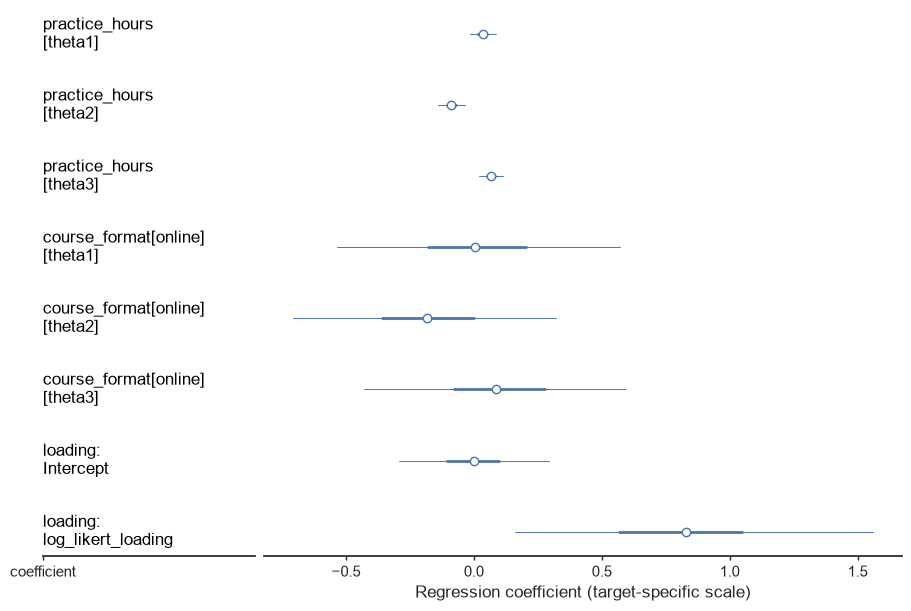

In [8]:
for name, fitted in [("Baseline", baseline), ("Explanatory", model)]:
    print(name, "— full measurement coefficients")
    with pd.option_context("display.max_rows", None, "display.max_columns", None):
        display(fc.coef(fitted, round_to=3))
    print(name, "— full regression coefficients")
    with pd.option_context("display.max_rows", None, "display.max_columns", None):
        display(fc.coef(fitted, component="regression", round_to=3))

coefficient_data = model.idata["parameter_data/regression_coefficient"].to_dataset()
traits = model.idata["design"]["trait"].values
labels = [
    f"{term}\n[{traits[int(trait)]}]" if trait >= 0 else f"{target}:\n{term}"
    for target, term, trait in zip(
        coefficient_data.target_kind.values,
        coefficient_data.term.values,
        coefficient_data.trait_index.values,
        strict=True,
    )
]
coefficients = (
    model.idata["posterior"]["regression_coefficient"]
    .assign_coords(coefficient=("regression_coefficient_id", labels))
    .swap_dims({"regression_coefficient_id": "coefficient"})
)
azp.plot_forest(
    coefficients.to_dataset(),
    combined=True,
    ci_kind="hdi",
    ci_probs=(0.5, 0.95),
    point_estimate="mean",
    labels=["coefficient"],
    backend="matplotlib",
    figure_kwargs={"figsize": (9, 6), "layout": "constrained"},
)
plt.gcf().axes[-1].set_xlabel("Regression coefficient (target-specific scale)")
plt.show()

For `theta2`, practice hours have a conditional association of -0.088 trait units per hour (95% HDI -0.139 to -0.036); for `theta3`, the association is 0.065 (0.020 to 0.113). The `theta1` interval includes zero. The course-format intervals are wide and include zero for all three traits. That contrast describes finite-sample associations with an independently generated teaching label.

The statement log-loading slope is 0.831 (95% HDI 0.162 to 1.559), indicating a positive association with the known Likert-loading predictor in this synthetic case. Remaining log-loading SD is 0.263 (0.030 to 0.487).

## Compare response calibration and score precision

Both models predict the same named dyad and use the same response observation
unit. Compare predictive calibration, the overall Pearson check and reliability
with their diagnostic and finite-sample limits. Adding predictors need not
improve any of these summaries. Reliability concerns existing-person score
precision, rather than the truth of a regression relationship.

The default ratio reliability is $V/(V+U)$: $V$ is the variance of posterior-mean scores across people, and $U$ is their mean posterior variance.

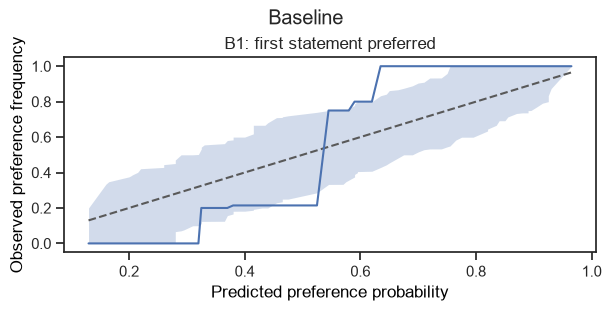

Overall PPP: 0.455


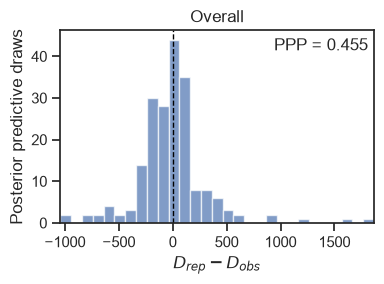

,reliability,score_variance,mean_posterior_variance,n_person
trait,,,,
theta1,0.549,0.513,0.421,80
theta2,0.662,0.673,0.343,80
theta3,0.719,0.762,0.298,80


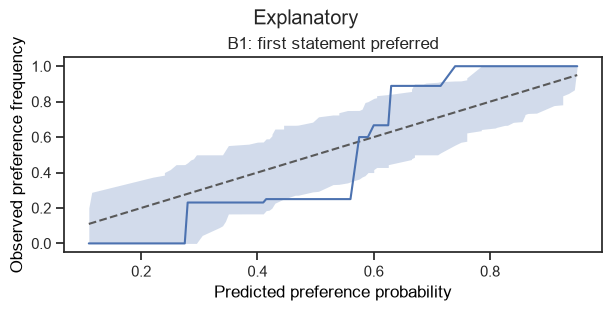

Overall PPP: 0.505


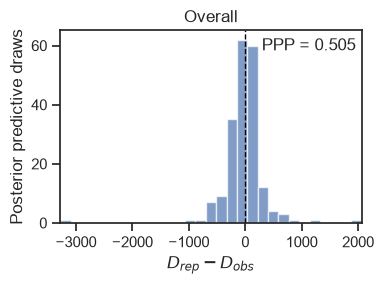

,reliability,score_variance,mean_posterior_variance,n_person
trait,,,,
theta1,0.538,0.542,0.467,80
theta2,0.719,0.947,0.370,80
theta3,0.731,0.956,0.351,80


In [9]:
for name, fitted in [("Baseline", baseline), ("Explanatory", model)]:
    predictions = fc.posterior_predictive(fitted, draws=200, random_seed=44, progressbar=False)
    view = fc.predictive_view(predictions, block="B1")
    azp.plot_ppc_pava(
        view,
        data_type="binary",
        backend="matplotlib",
        figure_kwargs={"figsize": (6, 3), "layout": "constrained"},
    )
    plt.gca().set(
        title="B1: first statement preferred",
        xlabel="Predicted preference probability",
        ylabel="Observed preference frequency",
    )
    plt.gcf().suptitle(name)
    plt.show()
    check = fc.chi_ppp(fitted, predictions=predictions)
    print("Overall PPP:", round(float(check["PPP"]), 3))
    fc.plot_ppp(check, quantile_range=(0.005, 0.995))
    plt.show()
    display(fc.reliability(fitted).to_dataframe().round(3))

The overall Pearson PPP is 0.455 for the baseline and 0.505 for the explanatory model. Neither is extreme for this discrepancy, but an overall check can miss local patterns: inspect the B1 calibration curves as well. These PPPs use 200 posterior predictive draws; their difference is not evidence for preferring a model.

Ratio reliability changes differently across traits. For `theta2` it is 0.662 in the baseline and 0.719 in the explanatory model; for `theta1` it is 0.549 and 0.538. Predictor structure can change the spread of individual scores as well as their uncertainty, so higher reliability alone does not validate a regression relationship. This comparison changes both the ability mean regression and the conditional prior on loadings.

## Separate residual and marginal variation

Both models fix conditional trait residual SDs to one. Predictor variation can
change marginal population SDs and correlations across the calibration cohort.
These population moments differ from the SD of posterior-mean individual scores.
Fixed values have no posterior uncertainty and display missing interval entries.

In [10]:
for name, fitted in [("Baseline", baseline), ("Explanatory", model)]:
    print(name, "— marginal means and SDs")
    moments = fc.trait_summary(fitted)
    interval = ["mean", "sd", "hdi95_lb", "hdi95_ub"]
    display(
        moments[["trait_mean", "trait_sd"]]
        .sel(summary=interval)
        .to_dataframe()
        .unstack("summary")
        .round(3)
    )
    print(name, "— marginal trait correlations")
    display(
        moments.trait_correlation.sel(summary=["mean", "hdi95_lb", "hdi95_ub"])
        .to_dataframe()
        .unstack("summary")
        .round(3)
    )

Baseline — marginal means and SDs


trait_mean                       trait_sd                      
summary       mean  sd hdi95_lb hdi95_ub     mean  sd hdi95_lb hdi95_ub
trait                                                                  
theta1         0.0 NaN      NaN      NaN      1.0 NaN      NaN      NaN
theta2         0.0 NaN      NaN      NaN      1.0 NaN      NaN      NaN
theta3         0.0 NaN      NaN      NaN      1.0 NaN      NaN      NaN

Baseline — marginal trait correlations


trait_correlation                  
summary                       mean hdi95_lb hdi95_ub
trait  trait_aux                                    
theta1 theta1                1.000      NaN      NaN
       theta2                0.152   -0.218    0.540
       theta3                0.161   -0.234    0.563
theta2 theta1                0.152   -0.218    0.540
       theta2                1.000      NaN      NaN
       theta3                0.053   -0.294    0.395
theta3 theta1                0.161   -0.234    0.563
       theta2                0.053   -0.294    0.395
       theta3                1.000      NaN      NaN

Explanatory — marginal means and SDs


trait_mean                          trait_sd                         
summary       mean     sd hdi95_lb hdi95_ub     mean     sd hdi95_lb hdi95_ub
trait                                                                        
theta1       0.002  0.136   -0.255    0.271    1.044  0.038    1.000     1.12
theta2      -0.088  0.126   -0.335    0.153    1.162  0.078    1.022     1.31
theta3       0.042  0.125   -0.205    0.283    1.096  0.055    1.004     1.20

Explanatory — marginal trait correlations


trait_correlation                  
summary                       mean hdi95_lb hdi95_ub
trait  trait_aux                                    
theta1 theta1                1.000      NaN      NaN
       theta2                0.232   -0.114    0.592
       theta3                0.213   -0.173    0.598
theta2 theta1                0.232   -0.114    0.592
       theta2                1.000      NaN      NaN
       theta3                0.076   -0.266    0.420
theta3 theta1                0.213   -0.173    0.598
       theta2                0.076   -0.266    0.420
       theta3                1.000      NaN      NaN

Baseline marginal SDs are exactly one, with no interval because they are fixed. In the explanatory model, marginal SDs are 1.044, 1.162 and 1.096 for `theta1`–`theta3`. They include variation in predictor-dependent means across these 80 people; conditional residual SDs remain one. The marginal means and correlations use that same cohort distribution, while the reference-person mean at centered hours and `in_person` remains zero.

The [covariate API](../reference/generated/pyfcirt.Regression.md) describes
interactions, explicit priors and other supported targets.